<a href="https://colab.research.google.com/github/vivmish007/githubprectice-1/blob/main/Phase_Portrait_of_Nonlinear_Damped_Pendulum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

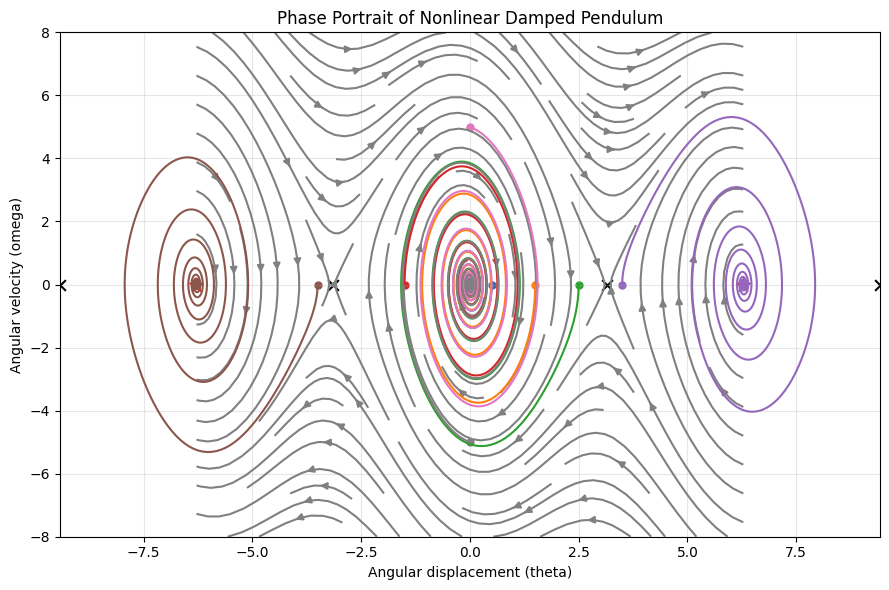

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
# Pendulum parameters
m, L, c, g = 1.0, 1.0, 0.5, 9.81
# Nonlinear state-space model
def pendulum(t, X):
    theta, omega = X
    return [omega, -(c/(m*L**2))*omega - (g/L)*np.sin(theta)]
# Phase plane
theta = np.linspace(-2*np.pi, 2*np.pi, 35)
omega = np.linspace(-8, 8, 35)
T, W = np.meshgrid(theta, omega)
U = W
V = -(c/(m*L**2))*W - (g/L)*np.sin(T)
plt.figure(figsize=(9, 6))
plt.streamplot(T, W, U, V, color='gray', density=1.2)
# Initial conditions
ics = [[0.5, 0], [1.5, 0], [2.5, 0],[-1.5, 0], [3.5, 0], [-3.5, 0],[0, 5], [0, -5]]
# Numerical integration
for x0 in ics:
    sol = solve_ivp(pendulum, [0, 20], x0, t_eval=np.linspace(0, 20, 1000))
    plt.plot(sol.y[0], sol.y[1])
    plt.scatter(*x0, s=25)
# Equilibrium points
for j in range(-2, 3):
    plt.scatter(2*j*np.pi, 0, color='red', marker='*', s=100)
    plt.scatter((2*j+1)*np.pi, 0, color='black', marker='x', s=60)
plt.xlabel('Angular displacement (theta)')
plt.ylabel('Angular velocity (omega)')
plt.title('Phase Portrait of Nonlinear Damped Pendulum')
plt.xlim(-3*np.pi, 3*np.pi)
plt.ylim(-8, 8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()